<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/14_IoT_IIoT_Attack_Detection/QPCA_QFL_IoHTIntrusion_Tokgoz2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QPCA + QNN / QSVM and federated QPCA + QNN for IoHT intrusion detection: Tokgoz and Mosaiyebzadeh (2026) step by step

This notebook re-implements, runs and checks the experiments of

> Emre Tokgoz and Fatemeh Mosaiyebzadeh, "Conventional and Quantum Feature Selection and Federated Learning Applications for
> Anomaly Detection in IoT Healthcare Networks", *Electronics* 15(19), 4469, 2026, DOI 10.3390/electronics15194469.

The paper publishes no code ("the source code ... is not publicly available"). Everything below is written from the paper's
Section 4 and Tables 2 to 4, and every place where the paper is silent is marked `# CHOICE:` in the code.

**What the notebook does.**
1. Downloads the public **WUSTL-EHMS-2020** dataset (Hady et al., IEEE Access 2020; 16,318 network + patient-sensor records,
   normal / spoofing / data-alteration traffic of an Internet-of-Healthcare-Things testbed).
2. Draws the paper's **matched sample** of 666 records (333 normal + 333 attack), splits it 80/20 (532 train / 134 test) and repeats everything for the paper's three seeds 42, 7, 13 and feature dimensions n = 2, 5, 10.
3. Builds the **classical pipeline** `StandardScaler -> PCA(n) -> ANN / DNN / SVM` and its **federated** version (3 hospitals, FedAvg, 10 rounds).
4. Builds the paper's **"QPCA"**: classical PCA, then every sample is encoded by a Qiskit `ZZFeatureMap` (2 repetitions, linear entanglement), run on `AerSimulator` with 1000 shots, and the measured bit-string probabilities (rescaled to [0, 1]) become the new features. The "QNN" is an `MLPClassifier` on these features, the "QSVM" an RBF `SVC`, and the federated model is FedAvg over three QNN clients. **These circuits are executed, drawn and counted in the circuit section further below.**
5. Re-draws the paper's convergence curves (Figs. 1 to 4), the federated per-round curves (Fig. 5) and compares **every number of Tables 3 and 4** with ours, claim by claim.

**How to run.** Colab, CPU runtime, Runtime -> Run all. `FAST_MODE = True` (default) finishes in a few minutes (two seeds, short federated rounds); `FAST_MODE = False` uses the paper's budgets (500 epochs, 3 seeds) plus 7 extra seeds for a steadier estimate (about 30 minutes on a CPU).

**What you get at the end.** A table of accuracy / precision / F1 mean +- std over seeds for all 10 model rows of the paper plus extra baselines, convergence and federated-round figures, and a verdict ("reproduced" / "not reached" / "exceeded" / "cannot be checked") for each of the paper's numbers and qualitative claims.

## The paper in one page

**Problem.** Detect attacks (spoofing, data alteration) on an Internet-of-Healthcare-Things (IoHT) network, where patient
sensor readings and network flows are mixed, without pooling the raw data of the hospitals (federated learning, FL).

**Decision.** Normal versus attack (the two attack categories are merged into one class).

**Method (Section 4).**
- Preprocessing: drop identifiers (addresses, MAC addresses, ports), label-encode `Flgs`, binarise the target, `StandardScaler`, SMOTE for the classical pipeline, feature selection by correlation ranking, "n in {2, 5, 10}".
- **Classical baselines**: PCA + ANN (MLP 64-32, ReLU), PCA + DNN (MLP 128-64-32), PCA + SVM (RBF, default C), 500 training iterations, no hyper-parameter search; federated PCA + ANN.
- **QPCA** (following the authors' earlier work [12]): *not* the phase-estimation algorithm of Lloyd et al. but "classical PCA followed by a ZZFeatureMap (linear entanglement), each sample individually encoded and measured via AerSimulator at 1000 shots, and the resulting measurement probabilities rescaled to [0, 1]".
- **QNN** = an `MLPClassifier` trained on the QPCA features (the paper says so itself in Section 4.5); **QSVM** = RBF SVM on the same features. **Federated QPCA + QNN**: 3 hospital clients with about 177 samples each, QPCA applied locally, local QNN with `warm_start`, FedAvg (custom) for 10 rounds.
- Protocol: **666 matched records** (333 per class), 80/20 stratified split (532 / 134), seeds 42, 7, 13 govern sample draw, split, initialisation and client partition; mean +- std over the three seeds.

**Claims we can test (abstract, Tables 3 and 4, Section 4).** PCA + ANN is the best classical model (76.6 % at n = 2); QPCA + QNN is the best centralised
quantum model (74.4 % at n = 2); PCA + SVM beats QPCA + QSVM at n = 10 (70.1 % versus 66.9 %); federated QPCA + QNN loses accuracy with dimension (62.9 % -> 54.7 %), is
10.7 to 15.2 points below its centralised counterpart and has the largest seed variance at n = 2 (std 15.2 points); classical federation costs at most about 3 points.

**Internal inconsistencies of the paper** (the notebook checks against Tables 3 and 4, which agree with the abstract): the running text of Sections 4.2 to 4.6 quotes different
numbers from the tables for several cells, for example QPCA + QNN 75.6 / 68.9 / 69.2 % (text) versus 74.4 / 69.2 / 69.9 % (Table 4); federated QPCA + QNN 62.9 / 57.2 / 55.7 % (text) versus 62.9 / 58.5 / 54.7 % (Table 4); PCA + SVM 68.2 % at n = 10 (text) versus 70.1 % (Table 3); federated PCA + ANN 67.4 % at n = 10 (text) versus 73.4 % (Table 3). The paper itself says that an earlier version had a PCA dimension-scaling error, which probably explains the mismatches.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | WUSTL-EHMS-2020 subset | the official WUSTL-EHMS-2020 CSV (16,318 records, 14,272 normal + 1,124 spoofing + 922 data alteration), downloaded over verified TLS |
| Matched sample | 666 records, 333 per class, seed governs the draw | the same; random draw without replacement of 333 normal and 333 attack records (attack records drawn from both attack categories together, `# CHOICE:` no stratification by category) |
| Split | 80/20 stratified (532 / 134) | the same, `train_test_split(..., stratify=y, random_state=seed)` |
| Seeds | 42, 7, 13 | the same (FAST_MODE: 42 and 7); the full run adds 7 extra seeds as a supplementary estimate |
| Dropped columns | addresses, MAC addresses, ports | `SrcAddr, DstAddr, SrcMac, DstMac, Sport, Dport` (both ports are port numbers) |
| Categorical | `Flgs` label-encoded | `Flgs` and `Dir` label-encoded (`# CHOICE:` `Dir` is also categorical text; in this CSV it has one value, so it is removed with the other constant columns `SrcGap, DstGap, DIntPktAct, dMinPktSz, Trans`); 31 model features remain |
| SMOTE | "for the classical pipeline" | **not used**: the matched sample is exactly balanced, so SMOTE would do nothing |
| Standardisation | `StandardScaler` | fitted on the training split only |
| Feature selection "n in {2, 5, 10}" | "correlation-based ranking" and "PCA scales its number of components with n" | primary pipeline `StandardScaler -> PCA(n)`; the correlation-ranking variant (top-n features by absolute correlation with the label, train split) is reported as an extra baseline (`# CHOICE:`) |
| ANN / DNN | MLP (64, 32) / (128, 64, 32), ReLU, 500 iterations | `MLPClassifier(hidden_layer_sizes=..., activation="relu", max_iter=500, random_state=seed)`; other settings are scikit-learn defaults (Adam, `alpha = 1e-4`, `tol = 1e-4`, early stop on loss plateau) |
| SVM | RBF, default regularisation | `SVC(kernel="rbf")` (C = 1, gamma = "scale") |
| QPCA input to the circuit | classical PCA scores; scaling not stated | scores `MinMaxScaler((0, pi))` fitted on train, test clipped to [0, pi] (`# CHOICE:`, repository convention) |
| Circuit | `ZZFeatureMap`, 2 reps, linear entanglement, 1000 shots, AerSimulator | `qiskit.circuit.library.zz_feature_map(n, reps=2, entanglement="linear")` + `measure_all()`, `AerSimulator(method="statevector")`, 1000 shots, seeded |
| QPCA output | "measurement probabilities rescaled to [0, 1]" | the 2^n bit-string frequencies, then `MinMaxScaler` fitted on the training features (test clipped); so n = 2 / 5 / 10 gives 4 / 32 / 1024 features per sample (`# CHOICE:`) |
| QNN | MLPClassifier on the quantum features (Section 4.5) | `MLPClassifier((64, 32), max_iter=500)` (`# CHOICE:` same architecture as the ANN, the paper gives no QNN architecture; Table 2 lists one "ANN" architecture and "all classical and quantum neural architectures share the same activation function") |
| QSVM | RBF SVM on the quantum features | `SVC(kernel="rbf")` on the quantum features |
| Federation | 3 hospital clients (177 to 178 samples), custom FedAvg, 10 rounds, `warm_start` | IID split of the 532 training samples into 3 parts (178 / 177 / 177), 10 rounds, every round each client trains `LOCAL_ITERS` epochs (`warm_start=True`) from the global weights, the server averages weights and biases weighted by client size. Local epochs per round (`# CHOICE:` 50 = 500 / 10 in the full run, 20 in FAST_MODE) |
| Federated initialisation | not stated | **shared** initial weights for all clients (standard FedAvg, `# CHOICE:` primary result). An ablation with **independent** client initialisations (what you get if each client builds its own `MLPClassifier` with a different random state) is also run, because averaging independently initialised networks is a plausible cause of the paper's poor and unstable federated quantum accuracy |
| "Validation" curves | train vs validation accuracy per epoch | validation = the 134 test samples, **monitoring only** (nothing is selected on it) |
| Metrics | accuracy, precision, F1, time | accuracy, precision, recall, F1 with **attack as the positive class** (the paper's precision and F1 values are consistent with this), mean +- std (ddof = 0) over seeds, wall-clock time of fit + predict (+ circuit execution for the quantum rows) |
| Hardware / shots | AerSimulator, 1000 shots | the same; an IBM device is never used (`IBM_TOKEN` is not needed) |

In [1]:
# Pinned to the versions this notebook was tested with. Colab already ships numpy, pandas, scikit-learn and matplotlib.
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
def _qiskit_ok():
    try:
        import qiskit, qiskit_aer, pylatexenc
        return qiskit.__version__ == "2.5.2" and qiskit_aer.__version__ == "0.17.2"
    except Exception:
        return False
if IN_COLAB or not _qiskit_ok():
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "qiskit==2.5.2", "qiskit-aer==0.17.2", "pylatexenc"], check=True)
    print("installed; if an import below fails, use Runtime -> Restart session and run again")
else:
    print("pinned versions already present")

pinned versions already present


In [2]:
# ------------------------------ configuration (every tunable constant lives here) ------------------------------
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")       # keep BLAS / OpenMP to one thread (shared machine)

FAST_MODE = False          # True: class demo (2 seeds, short federated rounds, short curves). False: paper budgets + 7 extra seeds.
SEED = 42                   # master seed (first of the paper's three seeds)
IBM_TOKEN = ""              # not used: the paper ran on AerSimulator

# --- paper parameters (Section 4.1, Table 2) ---
PAPER_SEEDS = [42, 7, 13]   # paper: three seeds
DIMS        = [2, 5, 10]    # paper: feature dimensions n
N_PER_CLASS = 333           # paper: 666 records, 333 per class
TEST_SIZE   = 0.20          # paper: 80/20 stratified -> 532 train / 134 test
SHOTS       = 1000          # paper: 1000 shots per sample
FM_REPS     = 2             # paper: ZZFeatureMap reps = 2
ENTANGLEMENT = "linear"     # paper: linear entanglement
HIDDEN_ANN  = (64, 32)      # paper: ANN MLP (64, 32), ReLU
HIDDEN_DNN  = (128, 64, 32) # paper: DNN MLP (128, 64, 32), ReLU
EPOCHS      = 500           # paper: 500 training iterations for every centralised model
N_CLIENTS   = 3             # paper: 3 hospital clients
ROUNDS      = 10            # paper: 10 federated rounds
TOL         = 2.0           # verdict tolerance in accuracy / precision / F1 points

if FAST_MODE:
    SEEDS = PAPER_SEEDS[:2]
    EXTRA_SEEDS = []
    LOCAL_ITERS = 20        # CHOICE: epochs per client and round (paper: not stated)
    CURVE_EPOCHS = 150      # epochs drawn in the convergence figures (paper: 500)
else:
    SEEDS = list(PAPER_SEEDS)
    EXTRA_SEEDS = [0, 1, 2, 3, 4, 5, 6]   # supplementary seeds, never mixed into the verdicts
    LOCAL_ITERS = 50        # CHOICE: 500 total epochs / 10 rounds
    CURVE_EPOCHS = 500
ALL_SEEDS = SEEDS + EXTRA_SEEDS

DATA_DIR  = "qc348_data"    # cache folder (created in the working directory)
DATA_PATH = None            # or the path of an uploaded wustl-ehms-2020_with_attacks_categories.csv
print("FAST_MODE =", FAST_MODE, "| seeds:", SEEDS, "+ extra", EXTRA_SEEDS, "| local epochs/round:", LOCAL_ITERS)

FAST_MODE = False | seeds: [42, 7, 13] + extra [0, 1, 2, 3, 4, 5, 6] | local epochs/round: 50


In [3]:
import time, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
import sklearn
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

import qiskit, qiskit_aer
from qiskit import transpile
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

np.random.seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60); pd.set_option("display.max_colwidth", 110)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| scikit-learn", sklearn.__version__,
      "| numpy", np.__version__, "| pandas", pd.__version__)

qiskit 2.5.2 | qiskit-aer 0.17.2 | scikit-learn 1.9.1 | numpy 2.5.4 | pandas 3.0.6


## 1. The data: WUSTL-EHMS-2020

The dataset (Hady, Ghubaish, Salman, Unal and Jain, IEEE Access 8, 2020) was captured on a real-time testbed in which patient-monitoring
sensors (temperature, SpO2, pulse, blood pressure, heart rate, respiration, ECG ST segment) send readings through a gateway to a server, while an
attacker performs **spoofing** and **data alteration** attacks. Each record is a network flow (Argus features) joined with the patient's
vital signs. The official CSV (`wustl-ehms-2020_with_attacks_categories.csv`, 16,318 rows x 45 columns) is downloaded over verified TLS; if your
network blocks the download, download the file from <https://www.cse.wustl.edu/~jain/ehms/> (or the Kaggle mirror) and set `DATA_PATH`
(in Colab the notebook offers a file-upload prompt). No data is ever generated or replaced.

In [4]:
WUSTL_URL = "https://www.cse.wustl.edu/~jain/ehms/ftp/wustl-ehms-2020_with_attacks_categories.csv"
CSV_NAME  = "wustl-ehms-2020_with_attacks_categories.csv"

def load_wustl():
    path = DATA_PATH or os.path.join(DATA_DIR, CSV_NAME)
    if not os.path.exists(path):
        import requests
        try:
            r = requests.get(WUSTL_URL, timeout=180); r.raise_for_status()      # verified TLS only
            with open(path, "wb") as f: f.write(r.content)
            print("downloaded %.2f MB from the official WUSTL page" % (len(r.content) / 1e6))
        except Exception as e:
            print("download failed (%s)." % type(e).__name__)
            if IN_COLAB:
                from google.colab import files
                print("Please upload", CSV_NAME, "(official WUSTL page or Kaggle mirror).")
                up = files.upload(); name = next(iter(up)); os.replace(name, path)
            else:
                raise RuntimeError("Download the CSV manually, then set DATA_PATH to its location.") from e
    else:
        print("using cached file", path)
    return pd.read_csv(path)

raw = load_wustl()
LABEL, CATEGORY = "Label", "Attack Category"
assert raw.shape == (16318, 45), raw.shape
assert raw[LABEL].value_counts().to_dict() == {0: 14272, 1: 2046}
print("raw shape:", raw.shape)

using cached file qc348_data\wustl-ehms-2020_with_attacks_categories.csv


raw shape: (16318, 45)


### Cleaning and labels

As in the paper: identifiers (source and destination addresses, MAC addresses, port numbers) are dropped because they carry no
generalisable signal, `Flgs` (and the direction field `Dir`) are label-encoded, the target is binarised (0 = normal, 1 = attack, merging **spoofing** and **data alteration**).
The original three-way category is kept only for plotting. The dataset has no missing values and no duplicates after this step; both are asserted.

In [5]:
ID_COLS = ["SrcAddr", "DstAddr", "Sport", "Dport", "SrcMac", "DstMac"]     # CHOICE: both Sport and Dport are port numbers -> dropped
feat = raw.drop(columns=ID_COLS + [LABEL, CATEGORY]).copy()
for c in ["Dir", "Flgs"]:                                                    # CHOICE: Dir is categorical text too
    vals = sorted(feat[c].astype(str).str.strip().unique())
    feat[c] = feat[c].astype(str).str.strip().map({v: i for i, v in enumerate(vals)})
    print(c, "->", {v: i for i, v in enumerate(vals)})
feat = feat.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
assert feat.isna().sum().sum() == 0 and not feat.duplicated().any()
const = [c for c in feat.columns if feat[c].nunique() == 1]
feat = feat.drop(columns=const)
print("dropped constant columns:", const)
FEATURE_NAMES = list(feat.columns)
X_all = feat.values.astype(float)
y_all = raw[LABEL].values.astype(int)                  # 0 normal, 1 attack
cat_all = raw[CATEGORY].values                         # normal / Spoofing / Data Alteration
print("feature matrix:", X_all.shape, "| binary labels:", np.bincount(y_all), "| categories:", dict(pd.Series(cat_all).value_counts()))

Dir -> {'->': 0}
Flgs -> {'M': 0, 'M *': 1, 'M d': 2, 'MR': 3, 'e': 4, 'e s': 5, 'eR': 6}


dropped constant columns: ['Dir', 'SrcGap', 'DstGap', 'DIntPktAct', 'dMinPktSz', 'Trans']
feature matrix: (16318, 31) | binary labels: [14272  2046] | categories: {'normal': np.int64(14272), 'Spoofing': np.int64(1124), 'Data Alteration': np.int64(922)}


## 2. Matched sample, split and train-only transforms

For every seed: draw 333 normal and 333 attack records at random, split 80/20 stratified (532 train / 134 test), then fit **on the training split only**
`StandardScaler -> PCA(n)`, the angle scaler (`MinMaxScaler((0, pi))`) and later the probability scaler. `make_inputs` returns everything a model could need for one (seed, n).

In [6]:
def draw_sample(seed):
    r = np.random.default_rng(seed)
    i0 = r.choice(np.flatnonzero(y_all == 0), N_PER_CLASS, replace=False)
    i1 = r.choice(np.flatnonzero(y_all == 1), N_PER_CLASS, replace=False)
    idx = np.concatenate([i0, i1])
    tr, te = train_test_split(idx, test_size=TEST_SIZE, stratify=y_all[idx], random_state=seed)
    return tr, te

def make_inputs(seed, n):
    """All train-only transforms for one seed and one dimension n."""
    tr, te = draw_sample(seed)
    sc = StandardScaler().fit(X_all[tr])
    Str, Ste = sc.transform(X_all[tr]), sc.transform(X_all[te])
    pca = PCA(n_components=n, random_state=seed).fit(Str)
    Ztr, Zte = pca.transform(Str), pca.transform(Ste)                       # classical PCA scores
    mm = MinMaxScaler((0, np.pi)).fit(Ztr)                                  # CHOICE: angles in [0, pi]
    Atr, Ate = mm.transform(Ztr), np.clip(mm.transform(Zte), 0, np.pi)
    # correlation-ranking variant (extra baseline): top-n features by |corr| with the label, train split only
    corr = np.abs([np.corrcoef(Str[:, j], y_all[tr])[0, 1] if Str[:, j].std() > 0 else 0 for j in range(Str.shape[1])])
    top = np.argsort(-np.nan_to_num(corr))[:n]
    return dict(seed=seed, n=n, tr=tr, te=te, ytr=y_all[tr], yte=y_all[te], Str=Str, Ste=Ste, Ztr=Ztr, Zte=Zte,
                Atr=Atr, Ate=Ate, Ctr=Str[:, top], Cte=Ste[:, top], top=top, pca=pca)

tr, te = draw_sample(SEED)
print("seed", SEED, "-> train", len(tr), "test", len(te), "| train class counts", np.bincount(y_all[tr]), "| test class counts", np.bincount(y_all[te]))
assert len(tr) == 532 and len(te) == 134

seed 42 -> train 532 test 134 | train class counts [266 266] | test class counts [67 67]


## Dataset Exploration and Visualisation

Everything here uses the **real** WUSTL-EHMS-2020 records and their ground-truth labels. First the shape, features and label values, then the class distribution, then a 2-D scatter of the
real records of the matched sample (seed 42): the first two principal components fitted on the training split (raw coordinates) and the same coordinates scaled to [0, pi] (the rotation angles of the circuit),
coloured by the original three-way attack family (normal, spoofing, data alteration).

shape of the full dataset: (16318, 45) | model features after cleaning: 31
feature names: ['Flgs', 'SrcBytes', 'DstBytes', 'SrcLoad', 'DstLoad', 'SIntPkt', 'DIntPkt', 'SIntPktAct', 'SrcJitter', 'DstJitter', 'sMaxPktSz', 'dMaxPktSz', 'sMinPktSz', 'Dur', 'TotPkts', 'TotBytes', 'Load', 'Loss', 'pLoss', 'pSrcLoss', 'pDstLoss', 'Rate', 'Packet_num', 'Temp', 'SpO2', 'Pulse_Rate', 'SYS', 'DIA', 'Heart_rate', 'Resp_Rate', 'ST']
original binary labels: {0: 14272, 1: 2046} (0 = normal, 1 = attack)
original attack categories: {'normal': 14272, 'Spoofing': 1124, 'Data Alteration': 922}


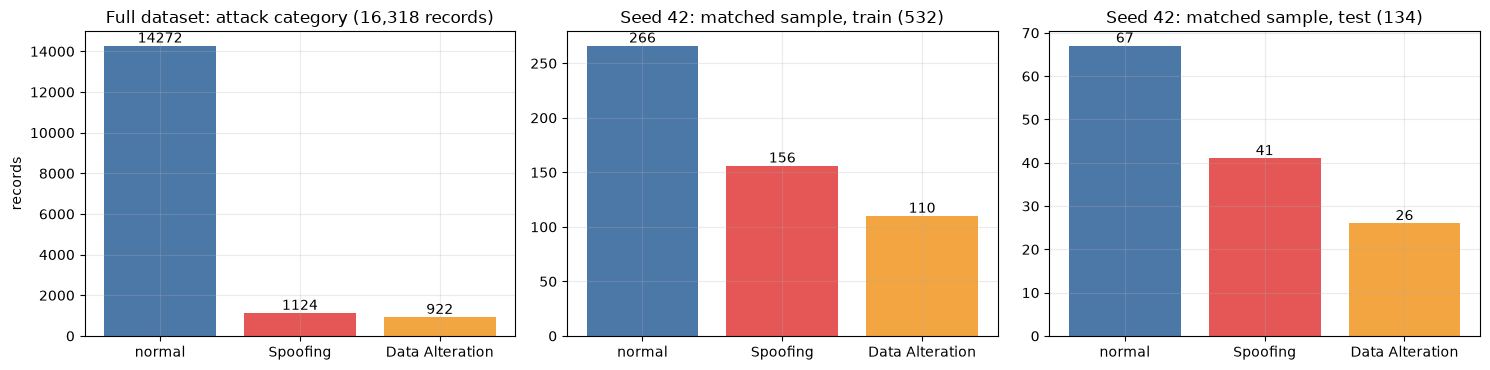

The binary task is exactly balanced by construction (333 + 333), but the attack half is a random mix of spoofing and data-alteration records.


In [7]:
print("shape of the full dataset:", raw.shape, "| model features after cleaning:", X_all.shape[1])
print("feature names:", FEATURE_NAMES)
print("original binary labels:", raw[LABEL].value_counts().sort_index().to_dict(), "(0 = normal, 1 = attack)")
print("original attack categories:", raw[CATEGORY].value_counts().to_dict())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
COL = {"normal": "#4c78a8", "Spoofing": "#e45756", "Data Alteration": "#f2a541"}
vc = raw[CATEGORY].value_counts()
ax[0].bar(vc.index, vc.values, color=[COL[k] for k in vc.index]); ax[0].set_title("Full dataset: attack category (16,318 records)")
for i, v in enumerate(vc.values): ax[0].text(i, v, str(v), ha="center", va="bottom")
ax[0].set_ylabel("records")
tr_, te_ = draw_sample(SEED)
for j, (nm, ids_) in enumerate([("matched sample, train (532)", tr_), ("matched sample, test (134)", te_)]):
    c_ = pd.Series(cat_all[ids_]).value_counts().reindex(["normal", "Spoofing", "Data Alteration"]).fillna(0)
    ax[1 + j].bar(c_.index, c_.values, color=[COL[k] for k in c_.index]); ax[1 + j].set_title(f"Seed {SEED}: {nm}")
    for i, v in enumerate(c_.values): ax[1 + j].text(i, v, str(int(v)), ha="center", va="bottom")
plt.tight_layout(); plt.show()
print("The binary task is exactly balanced by construction (333 + 333), but the attack half is a random mix of spoofing and data-alteration records.")

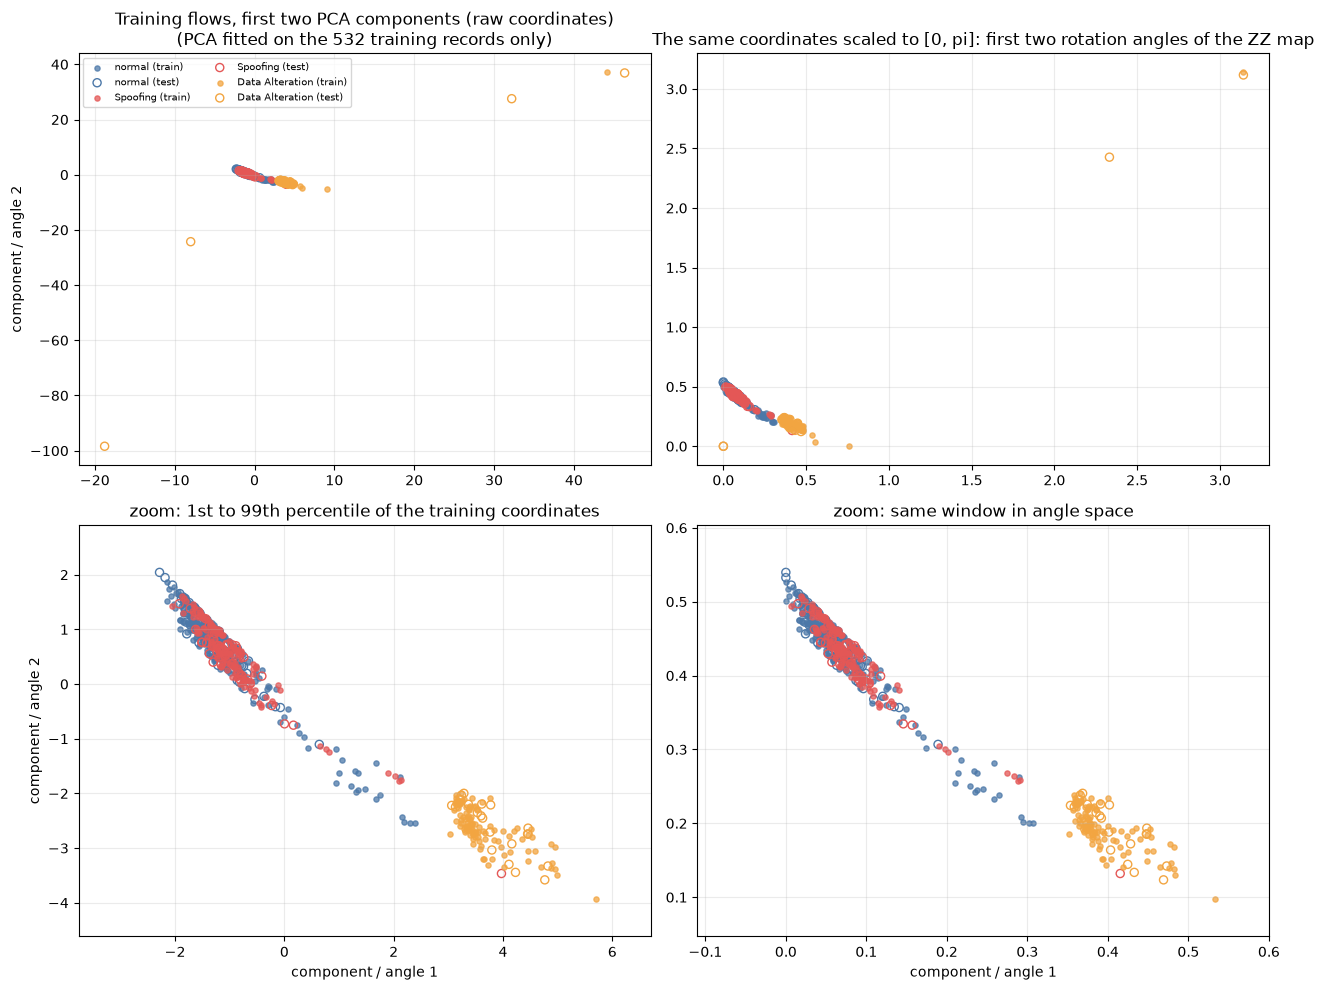

heavy tails: the largest |PC1| among training records is 44.1 against a median |PC1| of 1.40
explained variance ratio of the first 10 components (train): [0.348 0.213 0.115 0.084 0.047 0.036 0.034 0.033 0.029 0.018]
n = 2 keeps 56.1 % of the variance, n = 5 keeps 80.6 %, n = 10 keeps 95.6 %


In [8]:
d10 = make_inputs(SEED, 10)                       # PCA(10): its first two components are PCA(2)'s components
fig, ax = plt.subplots(2, 2, figsize=(13, 10))
for nm, c in COL.items():
    mtr = cat_all[d10["tr"]] == nm
    mte = cat_all[d10["te"]] == nm
    for r_ in range(2):
        ax[r_, 0].scatter(d10["Ztr"][mtr, 0], d10["Ztr"][mtr, 1], s=14, c=c, alpha=0.75, label=f"{nm} (train)")
        ax[r_, 0].scatter(d10["Zte"][mte, 0], d10["Zte"][mte, 1], s=34, facecolors="none", edgecolors=c, label=f"{nm} (test)")
        ax[r_, 1].scatter(d10["Atr"][mtr, 0], d10["Atr"][mtr, 1], s=14, c=c, alpha=0.75)
        ax[r_, 1].scatter(d10["Ate"][mte, 0], d10["Ate"][mte, 1], s=34, facecolors="none", edgecolors=c)
ax[0, 0].set_title("Training flows, first two PCA components (raw coordinates)\n(PCA fitted on the 532 training records only)")
ax[0, 1].set_title("The same coordinates scaled to [0, pi]: first two rotation angles of the ZZ map")
# bottom row: zoom on the bulk of the training data (a few heavy-tailed records stretch the full-range axes)
for col, key in ((0, "Ztr"), (1, "Atr")):
    lo, hi = np.percentile(d10[key][:, :2], 1, axis=0), np.percentile(d10[key][:, :2], 99, axis=0); pad = 0.25 * (hi - lo)
    ax[1, col].set_xlim(lo[0] - pad[0], hi[0] + pad[0]); ax[1, col].set_ylim(lo[1] - pad[1], hi[1] + pad[1])
ax[1, 0].set_title("zoom: 1st to 99th percentile of the training coordinates"); ax[1, 1].set_title("zoom: same window in angle space")
ax[0, 0].legend(fontsize=7, ncol=2)
for a_ in ax[1]: a_.set_xlabel("component / angle 1")
for a_ in ax[:, 0]: a_.set_ylabel("component / angle 2")
plt.tight_layout(); plt.show()
print("heavy tails: the largest |PC1| among training records is %.1f against a median |PC1| of %.2f" % (np.abs(d10["Ztr"][:, 0]).max(), np.median(np.abs(d10["Ztr"][:, 0]))))
print("explained variance ratio of the first 10 components (train):", np.round(d10["pca"].explained_variance_ratio_, 3))
print("n = 2 keeps %.1f %% of the variance, n = 5 keeps %.1f %%, n = 10 keeps %.1f %%" % tuple(100 * d10["pca"].explained_variance_ratio_[:k].sum() for k in (2, 5, 10)))

## Quantum Circuit Architecture

The only quantum circuit in the paper is the **ZZFeatureMap** (reps = 2, linear entanglement) that encodes one PCA sample per run on `n` qubits, followed by measurement of all qubits (1000 shots on `AerSimulator`).
The paper gives no variational ansatz: its "QNN" is a classical `MLPClassifier` trained on the measured probabilities, its "QSVM" a classical RBF `SVC` on the same probabilities, and its federated model averages the weights of that classical network.
So there are **no trainable circuit parameters**; the `n` circuit parameters are the data (angles). One circuit per distinct architecture (n = 2, 5, 10) is drawn below, exactly as it is executed (`measure_all` appended).

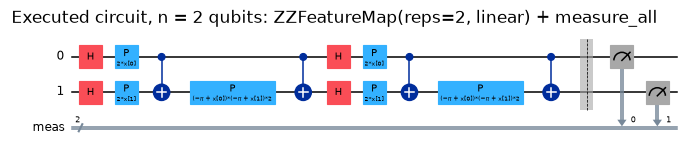

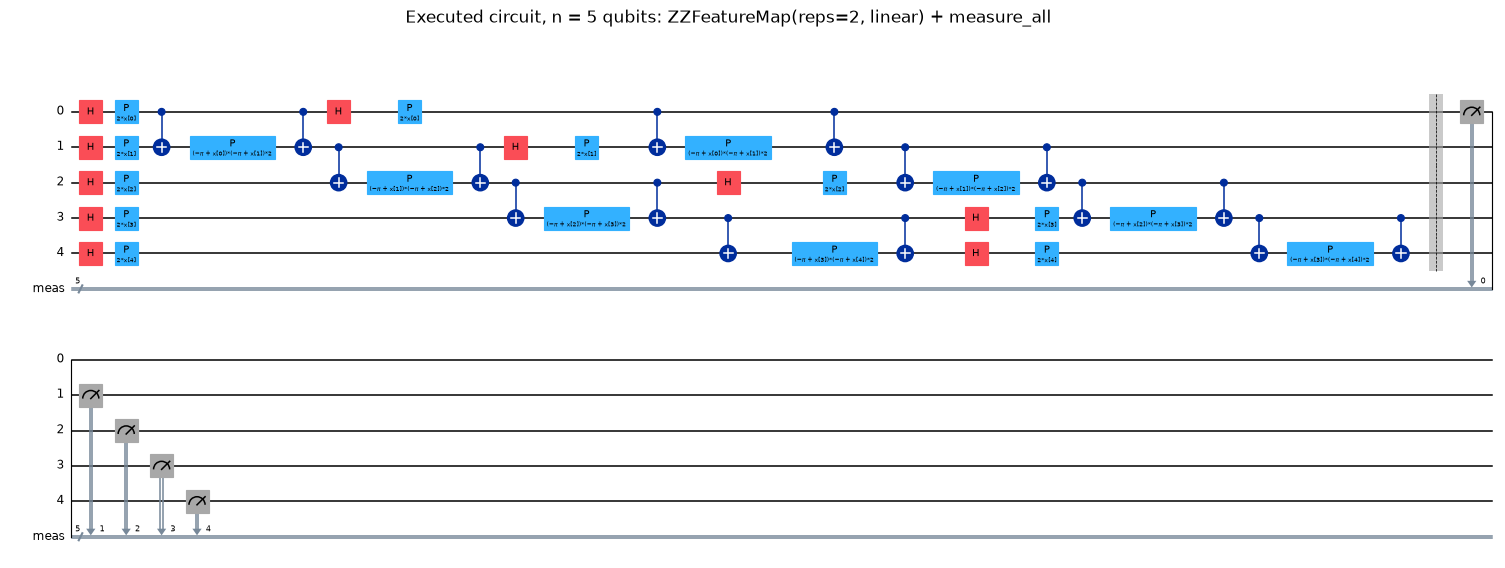

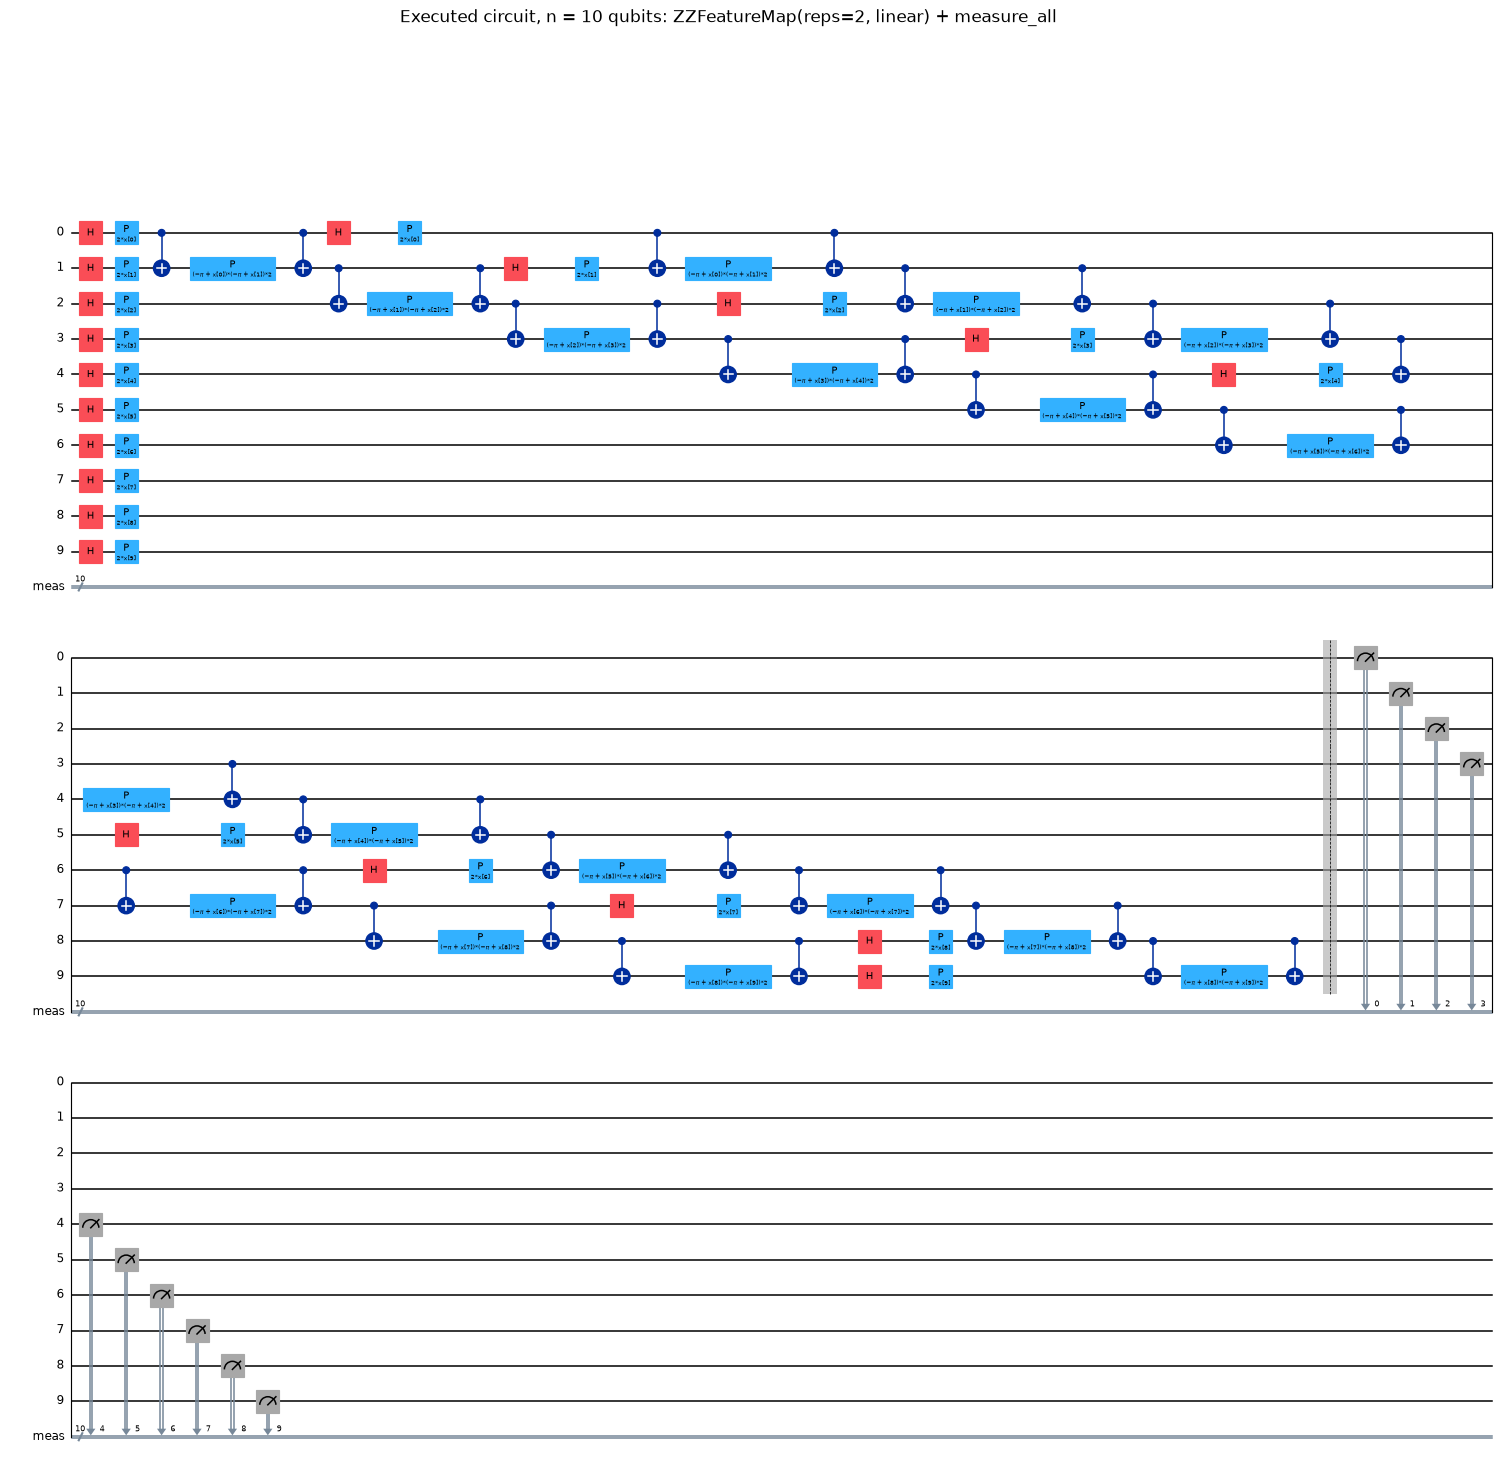

,n_qubits,depth_with_measurement,depth_feature_map,gates,data_parameters,trainable_parameters,output_features,shots
0,2,11,10,"{'p': 6, 'h': 4, 'cx': 4}",2,0,4,1000
1,5,23,22,"{'p': 18, 'cx': 16, 'h': 10}",5,0,32,1000
2,10,38,37,"{'p': 38, 'cx': 36, 'h': 20}",10,0,1024,1000


In [9]:
def feature_circuit(n):
    fm = zz_feature_map(n, reps=FM_REPS, entanglement=ENTANGLEMENT)       # the circuit of the paper (Table 2)
    return fm

def measured_circuit(n):
    qc = feature_circuit(n).copy(); qc.measure_all()                      # what is executed with 1000 shots
    return qc

sim = AerSimulator(method="statevector", max_parallel_threads=1)
_TCACHE = {}
def transpiled(n, kind):
    if (n, kind) not in _TCACHE:
        if kind == "counts":
            qc = measured_circuit(n)
        else:
            qc = feature_circuit(n).copy(); qc.save_probabilities()       # exact probabilities, used only for checks / ablation
        _TCACHE[(n, kind)] = transpile(qc, sim, optimization_level=0, seed_transpiler=SEED)
    return _TCACHE[(n, kind)]

def encode(A, n, seed, shots=SHOTS):
    """Run the real circuit on AerSimulator for every row of A (angles) and return the 2^n bit-string frequencies."""
    t = transpiled(n, "counts")
    res = sim.run([t.assign_parameters(a) for a in A], shots=shots, seed_simulator=seed).result()
    out = np.zeros((len(A), 2 ** n))
    for i in range(len(A)):
        for k, v in res.get_counts(i).items():
            out[i, int(k, 2)] = v / shots
    return out

rows = []
for n in DIMS:
    qc = measured_circuit(n)
    fig = qc.draw("mpl", fold=40, scale=0.55)
    fig.suptitle(f"Executed circuit, n = {n} qubits: ZZFeatureMap(reps={FM_REPS}, linear) + measure_all", y=1.0)
    display(fig); plt.close(fig)               # qiskit closes its figure, so display it explicitly
    fm = feature_circuit(n)
    rows.append(dict(n_qubits=qc.num_qubits, depth_with_measurement=qc.depth(), depth_feature_map=fm.depth(),
                     gates=dict(fm.count_ops()), data_parameters=fm.num_parameters, trainable_parameters=0,
                     output_features=2 ** n, shots=SHOTS))
display(pd.DataFrame(rows))

**Equivalence check.** The notebook never simulates the circuit with anything but Qiskit objects, so there is no hand-written simulator to validate. Two assertions still guard the pipeline: (i) the `AerSimulator` exact output
probabilities equal the reference `qiskit.quantum_info.Statevector` of the same circuit and angles, which also fixes the bit-order convention used by `encode`; (ii) the 1000-shot frequencies returned by `encode`
agree with those exact probabilities up to sampling noise (checked with 200,000 shots and, for 1000 shots, against a 6-sigma bound).

In [10]:
chk = np.random.default_rng(SEED)
for n in DIMS:
    A = chk.uniform(0, np.pi, size=(4, n))
    t = transpiled(n, "probs")
    res = sim.run([t.assign_parameters(a) for a in A]).result()
    for i, a in enumerate(A):
        exact_aer = np.asarray(res.data(i)["probabilities"])
        ref = Statevector(feature_circuit(n).assign_parameters(a)).probabilities()
        assert np.allclose(exact_aer, ref, atol=1e-10), (n, np.abs(exact_aer - ref).max())
    big = encode(A, n, SEED, shots=200_000)
    p_ex = np.stack([np.asarray(res.data(i)["probabilities"]) for i in range(len(A))])
    assert np.abs(big - p_ex).max() < 0.01, np.abs(big - p_ex).max()
    small = encode(A, n, SEED)                                             # the paper's 1000 shots
    bound = 6 * np.sqrt(np.maximum(p_ex, 1e-12) * (1 - p_ex) / SHOTS) + 2.0 / SHOTS
    assert np.all(np.abs(small - p_ex) <= bound), n
    assert np.allclose(small.sum(1), 1.0)
    print(f"n = {n:2d}: Aer exact probabilities == Statevector (1e-10); 200k-shot frequencies within {np.abs(big - p_ex).max():.4f}; 1000-shot frequencies within the 6-sigma bound")

n =  2: Aer exact probabilities == Statevector (1e-10); 200k-shot frequencies within 0.0023; 1000-shot frequencies within the 6-sigma bound


n =  5: Aer exact probabilities == Statevector (1e-10); 200k-shot frequencies within 0.0036; 1000-shot frequencies within the 6-sigma bound


n = 10: Aer exact probabilities == Statevector (1e-10); 200k-shot frequencies within 0.0005; 1000-shot frequencies within the 6-sigma bound


## 3. The "QPCA" features: PCA scores run through the circuit

For every (seed, n): `StandardScaler -> PCA(n) -> MinMax to [0, pi] -> ZZFeatureMap circuit -> 1000-shot frequencies -> MinMaxScaler to [0, 1]` (the last scaler fitted on the training features, test clipped).
The encoding time is recorded because the paper adds it to the quantum models' run time.

In [11]:
FEATS = {}
def build_features(seed, n):
    d = make_inputs(seed, n)
    t0 = time.time()
    Qtr = encode(d["Atr"], n, seed); Qte = encode(d["Ate"], n, seed)
    d["enc_time"] = time.time() - t0
    ps = MinMaxScaler().fit(Qtr)                                           # CHOICE: "rescaled to [0, 1]" = min-max on train
    d["Qtr"], d["Qte"] = ps.transform(Qtr), np.clip(ps.transform(Qte), 0, 1)
    d["Qraw_tr"], d["Qraw_te"] = Qtr, Qte
    return d

t0 = time.time()
for seed in ALL_SEEDS:
    for n in DIMS:
        FEATS[(seed, n)] = build_features(seed, n)
print("encoded %d (seed, n) combinations in %.1f s" % (len(FEATS), time.time() - t0))
d = FEATS[(SEED, 10)]
print("n = 10: quantum feature matrix", d["Qtr"].shape, "| non-zero bit-strings per sample (mean): %.0f of 1024" % (d["Qraw_tr"] > 0).sum(1).mean())

encoded 30 (seed, n) combinations in 434.2 s
n = 10: quantum feature matrix (532, 1024) | non-zero bit-strings per sample (mean): 324 of 1024


## 4. Models: classical, quantum and federated

All centralised neural models use `max_iter = 500`; there is no hyper-parameter search (as in the paper). Metrics take the **attack as the positive class**. The federated routine is a plain FedAvg:
the training split is divided into three IID client parts; each round every client continues training (`warm_start`) from the global weights for `LOCAL_ITERS` epochs; the server replaces the global weights and biases by the
client-size-weighted average. The global model is evaluated on the common test set after every round.

In [12]:
def metrics(y, p):
    return dict(acc=100 * accuracy_score(y, p), prec=100 * precision_score(y, p, zero_division=0),
                rec=100 * recall_score(y, p, zero_division=0), f1=100 * f1_score(y, p, zero_division=0))

def mlp(hidden, seed, **kw):
    return MLPClassifier(hidden_layer_sizes=hidden, activation="relu", max_iter=EPOCHS, random_state=seed, **kw)

def fit_eval(model, Xtr, ytr, Xte, yte, extra_time=0.0):
    t0 = time.time(); model.fit(Xtr, ytr); p = model.predict(Xte)
    return dict(metrics(yte, p), time=time.time() - t0 + extra_time), p

def fedavg(Xtr, ytr, Xte, yte, seed, shared_init=True, hidden=HIDDEN_ANN, extra_time=0.0):
    """Plain FedAvg of MLPClassifier clients. Returns final metrics, per-round test accuracy and the round-0 client accuracies."""
    t0 = time.time()
    parts = np.array_split(np.random.default_rng(seed).permutation(len(Xtr)), N_CLIENTS)   # IID, 178 / 177 / 177
    sizes = np.array([len(p) for p in parts], float)
    clients = [MLPClassifier(hidden_layer_sizes=hidden, activation="relu", max_iter=LOCAL_ITERS, warm_start=True,
                             random_state=seed if shared_init else seed + 1000 * (k + 1)) for k in range(N_CLIENTS)]
    glob = copy.deepcopy(clients[0]); round_acc = []
    for r in range(ROUNDS):
        for k, c in enumerate(clients):
            if r > 0:
                c.coefs_ = [w.copy() for w in glob.coefs_]; c.intercepts_ = [b.copy() for b in glob.intercepts_]
            c.fit(Xtr[parts[k]], ytr[parts[k]])
        w = sizes / sizes.sum()
        glob = copy.deepcopy(clients[0])
        glob.coefs_ = [sum(w[k] * clients[k].coefs_[l] for k in range(N_CLIENTS)) for l in range(len(clients[0].coefs_))]
        glob.intercepts_ = [sum(w[k] * clients[k].intercepts_[l] for k in range(N_CLIENTS)) for l in range(len(clients[0].intercepts_))]
        round_acc.append(100 * accuracy_score(yte, glob.predict(Xte)))
    out = dict(metrics(yte, glob.predict(Xte)), time=time.time() - t0 + extra_time)
    return out, round_acc

RES, ROUND_ACC = [], {}
def add(seed, n, model, r, rounds=None):
    RES.append(dict(seed=seed, n=n, model=model, **r))
    if rounds is not None: ROUND_ACC[(seed, n, model)] = rounds

t0 = time.time()
for seed in ALL_SEEDS:
    for n in DIMS:
        d = FEATS[(seed, n)]; ytr, yte, et = d["ytr"], d["yte"], d["enc_time"]
        # ---- classical (paper Table 3)
        r, _ = fit_eval(mlp(HIDDEN_ANN, seed), d["Ztr"], ytr, d["Zte"], yte); add(seed, n, "PCA+ANN", r)
        r, _ = fit_eval(mlp(HIDDEN_DNN, seed), d["Ztr"], ytr, d["Zte"], yte); add(seed, n, "PCA+DNN", r)
        r, _ = fit_eval(SVC(kernel="rbf"), d["Ztr"], ytr, d["Zte"], yte); add(seed, n, "PCA+SVM", r)
        r, ra = fedavg(d["Ztr"], ytr, d["Zte"], yte, seed, True); add(seed, n, "Fed PCA+ANN", r, ra)
        # ---- quantum (paper Table 4); time includes the circuit executions of train and test samples
        r, _ = fit_eval(mlp(HIDDEN_ANN, seed), d["Qtr"], ytr, d["Qte"], yte, et); add(seed, n, "QPCA+QNN", r)
        r, _ = fit_eval(SVC(kernel="rbf"), d["Qtr"], ytr, d["Qte"], yte, et); add(seed, n, "QPCA+QSVM", r)
        r, ra = fedavg(d["Qtr"], ytr, d["Qte"], yte, seed, True, extra_time=et); add(seed, n, "Fed QPCA+QNN", r, ra)
        # ---- ablation: independently initialised clients (see the choices table)
        r, ra = fedavg(d["Ztr"], ytr, d["Zte"], yte, seed, False); add(seed, n, "Fed PCA+ANN (indep. init)", r, ra)
        r, ra = fedavg(d["Qtr"], ytr, d["Qte"], yte, seed, False, extra_time=et); add(seed, n, "Fed QPCA+QNN (indep. init)", r, ra)
        # ---- extra baselines on identical inputs
        r, _ = fit_eval(RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=1), d["Ztr"], ytr, d["Zte"], yte); add(seed, n, "RF on PCA", r)
        r, _ = fit_eval(RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=1), d["Qtr"], ytr, d["Qte"], yte, et); add(seed, n, "RF on QPCA features", r)
        r, _ = fit_eval(mlp(HIDDEN_ANN, seed), d["Ctr"], ytr, d["Cte"], yte); add(seed, n, "Corr-top-n+ANN", r)
        r, _ = fit_eval(SVC(kernel="rbf"), d["Ctr"], ytr, d["Cte"], yte); add(seed, n, "Corr-top-n+SVM", r)
    # all standardised features (n-independent reference), stored under n = 0
    d = FEATS[(seed, 2)]
    r, _ = fit_eval(RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=1), d["Str"], d["ytr"], d["Ste"], d["yte"]); add(seed, 0, "RF on all features", r)
    r, _ = fit_eval(SVC(kernel="rbf"), d["Str"], d["ytr"], d["Ste"], d["yte"]); add(seed, 0, "SVM on all features", r)
    r, _ = fit_eval(mlp(HIDDEN_ANN, seed), d["Str"], d["ytr"], d["Ste"], d["yte"]); add(seed, 0, "ANN on all features", r)
    print("seed", seed, "done, elapsed %.0f s" % (time.time() - t0), flush=True)
res = pd.DataFrame(RES)
print(len(res), "result rows")

seed 42 done, elapsed 104 s


seed 7 done, elapsed 186 s


seed 13 done, elapsed 264 s


seed 0 done, elapsed 346 s


seed 1 done, elapsed 433 s


...

seed 3 done, elapsed 583 s


seed 4 done, elapsed 659 s


seed 5 done, elapsed 740 s


seed 6 done, elapsed 842 s


420 result rows


## 5. Results: mean +- std over the paper's seeds

Same layout as the paper's Tables 3 and 4 (accuracy, precision, F1 with the attack as positive class, run time). Values are percentages; `time` is wall-clock seconds on this machine (the quantum rows include the circuit executions).
The extra rows are baselines the paper does not have: a random forest on the same inputs, the correlation-ranking variant, models on all features, and the independent-initialisation federated ablation.

In [13]:
PRIMARY = res[res.seed.isin(SEEDS)]
def summarize(df):
    g = df.groupby(["n", "model"])
    out = pd.DataFrame({m: g[m].mean() for m in ["acc", "prec", "f1", "rec", "time"]})
    for m in ["acc", "prec", "f1"]:
        out[m + "_std"] = g[m].std(ddof=0)
    return out
S = summarize(PRIMARY)

ORDER = ["PCA+ANN", "PCA+DNN", "PCA+SVM", "Fed PCA+ANN", "QPCA+QNN", "QPCA+QSVM", "Fed QPCA+QNN",
         "Fed PCA+ANN (indep. init)", "Fed QPCA+QNN (indep. init)", "RF on PCA", "RF on QPCA features",
         "Corr-top-n+ANN", "Corr-top-n+SVM", "RF on all features", "SVM on all features", "ANN on all features"]
def fmt(n):
    sub = S.loc[n].reindex([m for m in ORDER if m in S.loc[n].index])
    return pd.DataFrame({"Accuracy": [f"{a:.1f} +- {s:.1f}" for a, s in zip(sub.acc, sub.acc_std)],
                         "Precision": [f"{a:.1f} +- {s:.1f}" for a, s in zip(sub.prec, sub.prec_std)],
                         "F1": [f"{a:.1f} +- {s:.1f}" for a, s in zip(sub.f1, sub.f1_std)],
                         "Time (s)": [f"{t:.2f}" for t in sub.time]}, index=sub.index)
for n in DIMS:
    print(f"\n===== Dimension n = {n}  (seeds {SEEDS}) =====")
    display(fmt(n))
print("\n===== Reference models on all features (n-independent) =====")
display(fmt(0))


===== Dimension n = 2  (seeds [42, 7, 13]) =====


,Accuracy,Precision,F1,Time (s)
model,,,,
PCA+ANN,72.6 +- 2.7,81.5 +- 6.6,68.4 +- 3.9,2.85
PCA+DNN,71.6 +- 6.0,79.5 +- 7.2,67.0 +- 7.9,5.39
PCA+SVM,72.9 +- 2.0,97.2 +- 2.2,63.4 +- 4.3,0.07
Fed PCA+ANN,71.9 +- 2.3,90.3 +- 4.7,63.5 +- 5.9,2.15
QPCA+QNN,70.9 +- 2.7,88.1 +- 6.3,62.4 +- 4.7,12.72
QPCA+QSVM,72.6 +- 2.3,97.2 +- 2.2,62.9 +- 5.0,8.18
Fed QPCA+QNN,71.6 +- 2.7,89.5 +- 5.4,63.3 +- 4.3,10.56
Fed PCA+ANN (indep. init),69.9 +- 2.3,77.8 +- 1.6,64.8 +- 3.9,1.03
Fed QPCA+QNN (indep. init),70.1 +- 3.2,84.2 +- 4.0,62.3 +- 5.5,9.11



===== Dimension n = 5  (seeds [42, 7, 13]) =====


,Accuracy,Precision,F1,Time (s)
model,,,,
PCA+ANN,78.6 +- 3.4,83.6 +- 3.5,76.9 +- 3.8,4.54
PCA+DNN,75.6 +- 6.0,79.1 +- 5.4,73.7 +- 7.3,6.61
PCA+SVM,74.9 +- 1.9,96.6 +- 2.4,67.2 +- 3.9,0.09
Fed PCA+ANN,73.1 +- 1.8,86.0 +- 6.8,67.5 +- 4.8,1.49
QPCA+QNN,74.4 +- 0.9,75.3 +- 1.5,73.9 +- 0.9,18.19
QPCA+QSVM,72.9 +- 3.7,86.2 +- 10.7,67.3 +- 4.7,12.79
Fed QPCA+QNN,70.4 +- 4.7,79.0 +- 6.8,65.3 +- 5.4,14.58
Fed PCA+ANN (indep. init),72.4 +- 2.2,80.2 +- 3.1,68.3 +- 3.4,1.38
Fed QPCA+QNN (indep. init),69.7 +- 4.0,75.2 +- 6.5,66.3 +- 3.8,13.91



===== Dimension n = 10  (seeds [42, 7, 13]) =====


,Accuracy,Precision,F1,Time (s)
model,,,,
PCA+ANN,79.9 +- 4.0,84.1 +- 4.1,78.4 +- 4.7,3.85
PCA+DNN,75.4 +- 3.7,78.0 +- 3.8,74.1 +- 4.3,5.40
PCA+SVM,74.6 +- 2.2,93.3 +- 6.3,67.7 +- 4.3,0.09
Fed PCA+ANN,76.6 +- 2.5,93.0 +- 2.6,71.0 +- 4.4,1.34
QPCA+QNN,71.1 +- 4.9,72.2 +- 6.3,70.8 +- 4.0,33.34
QPCA+QSVM,72.1 +- 2.9,75.4 +- 4.1,70.3 +- 3.6,29.44
Fed QPCA+QNN,70.4 +- 3.5,73.5 +- 6.0,68.6 +- 3.9,32.45
Fed PCA+ANN (indep. init),72.1 +- 1.9,81.6 +- 1.6,67.1 +- 3.2,1.05
Fed QPCA+QNN (indep. init),68.9 +- 6.6,74.1 +- 10.0,66.2 +- 5.3,32.31



===== Reference models on all features (n-independent) =====


,Accuracy,Precision,F1,Time (s)
model,,,,
RF on all features,78.6 +- 3.4,80.7 +- 1.9,77.7 +- 4.3,0.76
SVM on all features,76.6 +- 2.3,94.1 +- 5.4,70.8 +- 4.0,0.07
ANN on all features,79.1 +- 3.8,82.1 +- 4.5,78.1 +- 4.2,4.92


## 6. Re-drawing the paper's figures

**Figs. 1 to 4** (training versus validation accuracy per epoch for ANN, DNN and the centralised QPCA + QNN at n = 2 and n = 10, one representative seed): the "validation" curve is the accuracy on the 134 test samples and is used for monitoring only.
**Fig. 5** (federated test accuracy per round, mean +- std over seeds, by dimension) and a classical versus quantum comparison (the paper's Fig. 7).

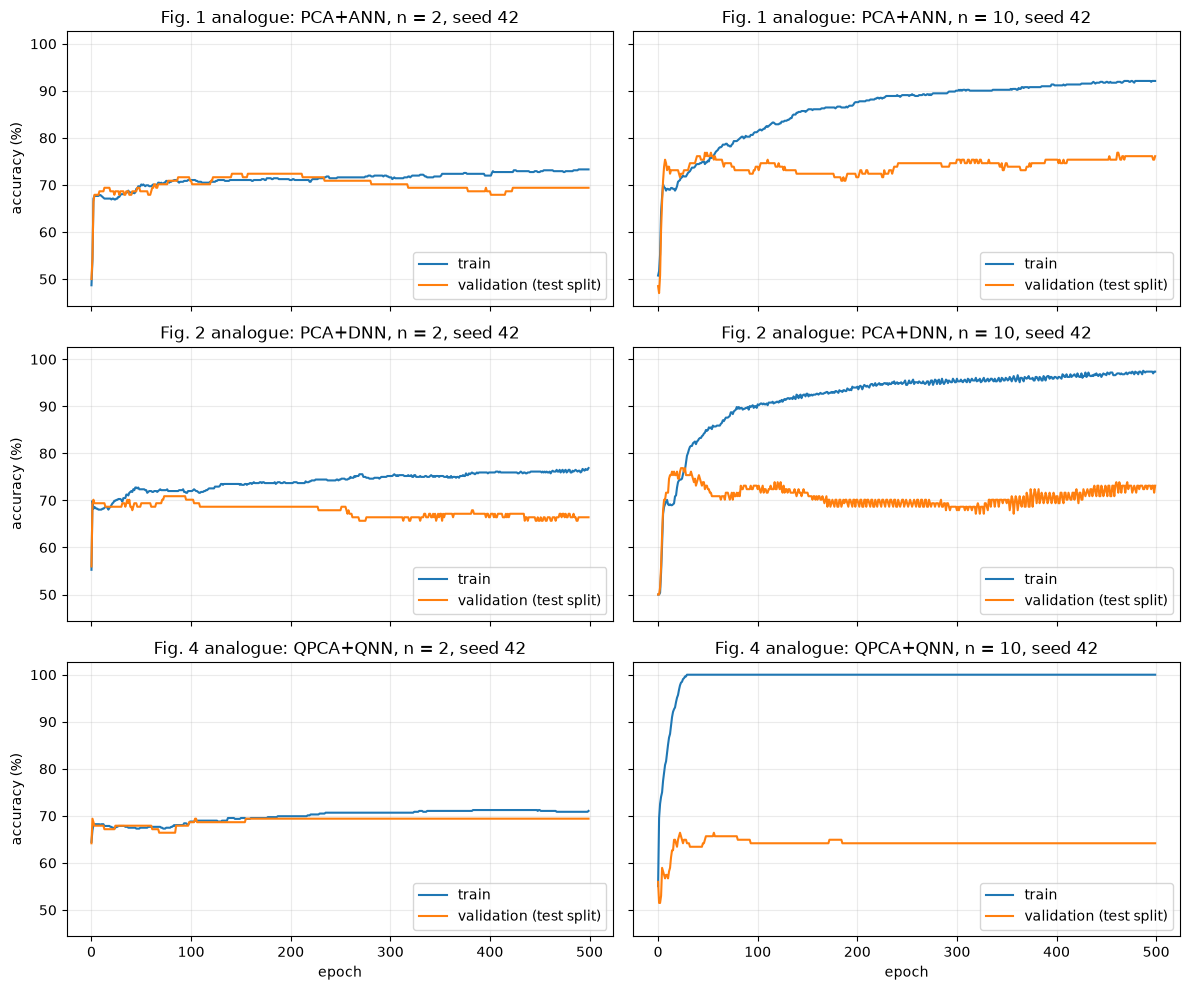

In [14]:
def curves(hidden, Xtr, ytr, Xte, yte, seed, epochs):
    m = MLPClassifier(hidden_layer_sizes=hidden, activation="relu", random_state=seed)
    a_tr, a_te = [], []
    for _ in range(epochs):
        m.partial_fit(Xtr, ytr, classes=[0, 1])
        a_tr.append(100 * m.score(Xtr, ytr)); a_te.append(100 * m.score(Xte, yte))
    return a_tr, a_te

fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharex=True, sharey=True)
for j, n in enumerate([2, 10]):
    d = FEATS[(SEED, n)]
    for i, (nm, hid, Xa, Xb) in enumerate([("Fig. 1 analogue: PCA+ANN", HIDDEN_ANN, d["Ztr"], d["Zte"]),
                                           ("Fig. 2 analogue: PCA+DNN", HIDDEN_DNN, d["Ztr"], d["Zte"]),
                                           ("Fig. 4 analogue: QPCA+QNN", HIDDEN_ANN, d["Qtr"], d["Qte"])]):
        a_tr, a_te = curves(hid, Xa, d["ytr"], Xb, d["yte"], SEED, CURVE_EPOCHS)
        axes[i, j].plot(a_tr, label="train"); axes[i, j].plot(a_te, label="validation (test split)")
        axes[i, j].set_title(f"{nm}, n = {n}, seed {SEED}"); axes[i, j].legend(loc="lower right")
        if j == 0: axes[i, j].set_ylabel("accuracy (%)")
for ax_ in axes[-1]: ax_.set_xlabel("epoch")
plt.tight_layout(); plt.show()

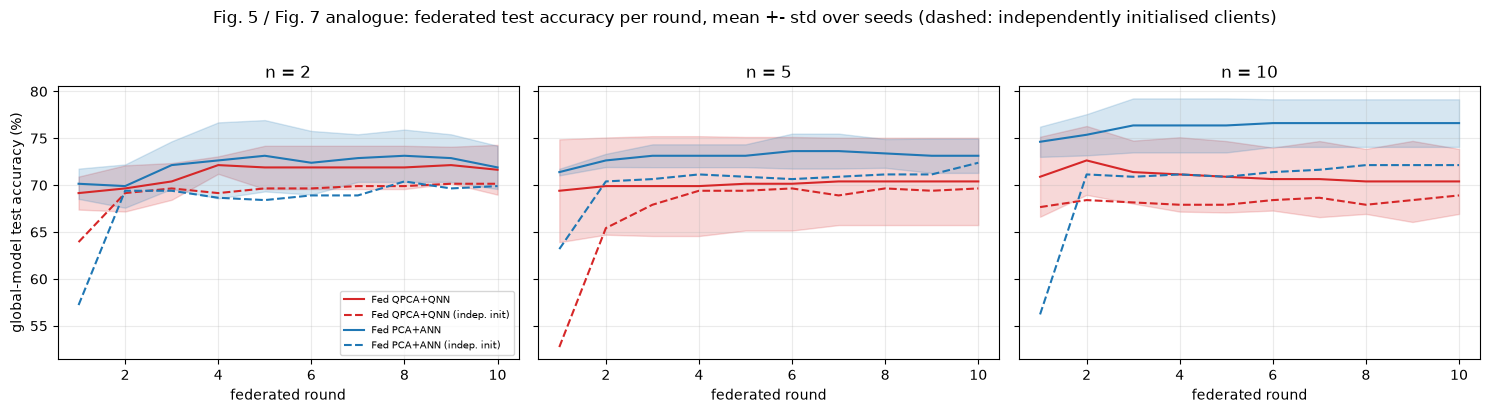

mean std across seeds of the federated quantum curve (shared init): {2: np.float64(2.1), 5: np.float64(4.99), 10: np.float64(3.77)}


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for j, n in enumerate(DIMS):
    for model, col, ls in [("Fed QPCA+QNN", "#d62728", "-"), ("Fed QPCA+QNN (indep. init)", "#d62728", "--"),
                           ("Fed PCA+ANN", "#1f77b4", "-"), ("Fed PCA+ANN (indep. init)", "#1f77b4", "--")]:
        M = np.array([ROUND_ACC[(s, n, model)] for s in SEEDS]); mu, sd = M.mean(0), M.std(0)
        x = np.arange(1, ROUNDS + 1)
        axes[j].plot(x, mu, color=col, ls=ls, label=model)
        if ls == "-": axes[j].fill_between(x, mu - sd, mu + sd, color=col, alpha=0.18)
    axes[j].set_title(f"n = {n}"); axes[j].set_xlabel("federated round")
    if j == 0: axes[j].set_ylabel("global-model test accuracy (%)")
axes[0].legend(fontsize=7, loc="lower right")
fig.suptitle("Fig. 5 / Fig. 7 analogue: federated test accuracy per round, mean +- std over seeds (dashed: independently initialised clients)", y=1.02)
plt.tight_layout(); plt.show()
sd_round = {n: np.array([ROUND_ACC[(s, n, "Fed QPCA+QNN")] for s in SEEDS]).std(0).mean() for n in DIMS}
print("mean std across seeds of the federated quantum curve (shared init):", {n: round(v, 2) for n, v in sd_round.items()})

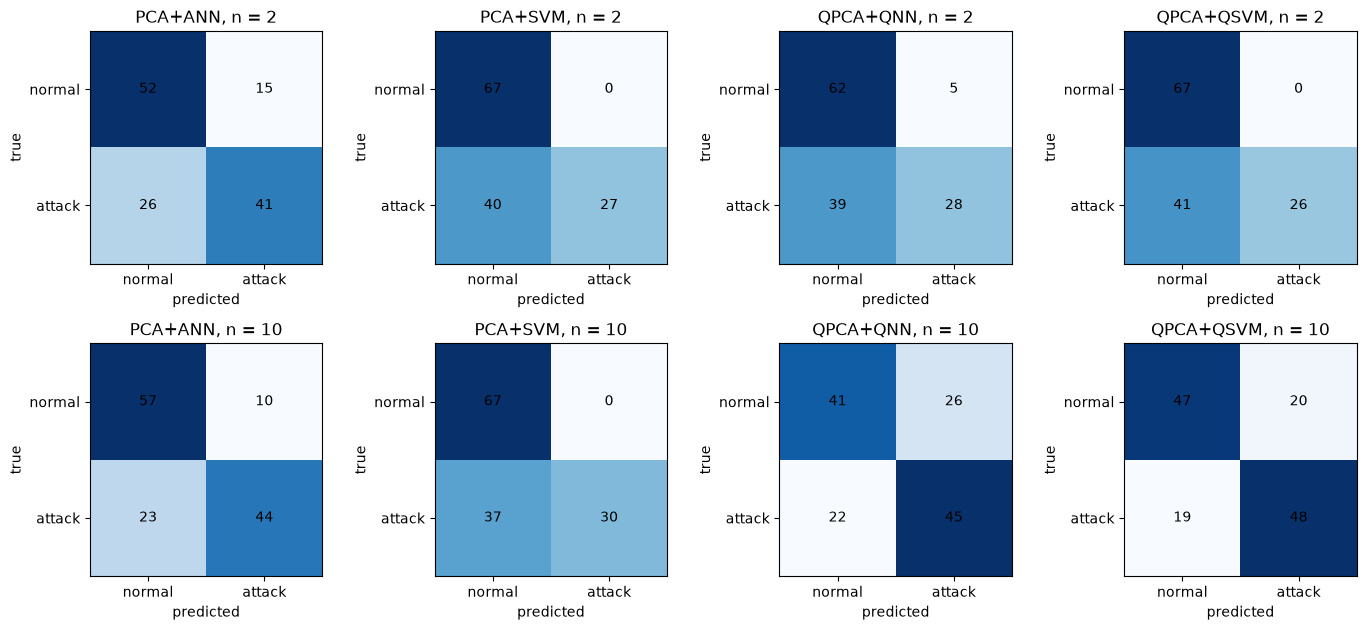

In [16]:
# confusion matrices (attack = positive class) of the main models, seed 42, n = 2 and n = 10, pooled over nothing: one real test set each
fig, axes = plt.subplots(2, 4, figsize=(14, 6.4))
for i, n in enumerate([2, 10]):
    d = FEATS[(SEED, n)]
    for j, (nm, mdl, A_, B_) in enumerate([("PCA+ANN", mlp(HIDDEN_ANN, SEED), d["Ztr"], d["Zte"]),
                                           ("PCA+SVM", SVC(), d["Ztr"], d["Zte"]),
                                           ("QPCA+QNN", mlp(HIDDEN_ANN, SEED), d["Qtr"], d["Qte"]),
                                           ("QPCA+QSVM", SVC(), d["Qtr"], d["Qte"])]):
        p = mdl.fit(A_, d["ytr"]).predict(B_); cm = confusion_matrix(d["yte"], p, labels=[0, 1])
        axes[i, j].imshow(cm, cmap="Blues"); axes[i, j].set_title(f"{nm}, n = {n}"); axes[i, j].grid(False)
        axes[i, j].set_xticks([0, 1], ["normal", "attack"]); axes[i, j].set_yticks([0, 1], ["normal", "attack"])
        for (a, b), v in np.ndenumerate(cm): axes[i, j].text(b, a, v, ha="center", va="center", color="black")
        axes[i, j].set_xlabel("predicted"); axes[i, j].set_ylabel("true")
plt.tight_layout(); plt.show()

## 7. Extra check: does shot noise matter?

The paper measures 1000 shots per sample. Because the simulator can also return the *exact* output probabilities (`save_probabilities`, asserted equal to `Statevector` above), we can rerun QPCA + QNN / QSVM on noise-free probabilities for the paper's seeds and see whether the sampling noise explains anything.

In [17]:
rows = []
for seed in SEEDS:
    for n in DIMS:
        d = FEATS[(seed, n)]; t = transpiled(n, "probs")
        def exact(A):
            r_ = sim.run([t.assign_parameters(a) for a in A]).result()
            return np.stack([np.asarray(r_.data(i)["probabilities"]) for i in range(len(A))])
        Etr, Ete = exact(d["Atr"]), exact(d["Ate"])
        ps = MinMaxScaler().fit(Etr); Etr, Ete = ps.transform(Etr), np.clip(ps.transform(Ete), 0, 1)
        r1, _ = fit_eval(mlp(HIDDEN_ANN, seed), Etr, d["ytr"], Ete, d["yte"]); r2, _ = fit_eval(SVC(), Etr, d["ytr"], Ete, d["yte"])
        rows.append(dict(seed=seed, n=n, **{"QNN, exact probs": r1["acc"], "QSVM, exact probs": r2["acc"]}))
ex = pd.DataFrame(rows)
cmp_ = ex.groupby("n").mean().drop(columns="seed")
cmp_["QNN, 1000 shots"] = PRIMARY[PRIMARY.model == "QPCA+QNN"].groupby("n").acc.mean()
cmp_["QSVM, 1000 shots"] = PRIMARY[PRIMARY.model == "QPCA+QSVM"].groupby("n").acc.mean()
print("accuracy (%), mean over seeds", SEEDS)
display(cmp_[["QNN, 1000 shots", "QNN, exact probs", "QSVM, 1000 shots", "QSVM, exact probs"]].round(1))

accuracy (%), mean over seeds [42, 7, 13]


,"QNN, 1000 shots","QNN, exact probs","QSVM, 1000 shots","QSVM, exact probs"
n,,,,
2,70.9,72.6,72.6,72.9
5,74.4,75.9,72.9,73.6
10,71.1,71.4,72.1,75.9


## 8. Side-by-side comparison with the paper, claim by claim

**Numeric claims.** Every accuracy, precision and F1 value of Tables 3 and 4 is compared with the mean over the paper's seeds (seeds 42, 7, 13 in the full run; the FAST run uses only two of them). Verdict: "reproduced" when the gap is within 2 points,
"not reached" when we are lower by more, "exceeded" when higher by more. Run times are not compared (different machine, different implementation) and are reported as "cannot be checked".
**Qualitative claims.** Orderings and trends stated in the abstract and Section 4 are checked on our means.

In [18]:
T3 = {2: {"PCA+ANN": (76.6, 80.0, 76.0, 1.6), "PCA+DNN": (75.9, 78.5, 75.3, 1.9), "PCA+SVM": (74.6, 79.7, 73.4, 3.7), "Fed PCA+ANN": (74.1, 74.6, 74.0, 3.0)},
      5: {"PCA+ANN": (73.9, 75.3, 73.5, 2.7), "PCA+DNN": (74.4, 76.2, 73.9, 0.9), "PCA+SVM": (71.1, 77.4, 69.4, 3.4), "Fed PCA+ANN": (73.1, 73.2, 73.1, 3.3)},
      10: {"PCA+ANN": (76.1, 77.6, 75.8, 2.7), "PCA+DNN": (75.6, 77.8, 75.1, 2.2), "PCA+SVM": (70.1, 75.8, 68.4, 0.7), "Fed PCA+ANN": (73.4, 74.1, 73.1, 4.7)}}
T4 = {2: {"QPCA+QNN": (74.4, 78.9, 74.5, 4.2), "QPCA+QSVM": (71.6, 73.3, 71.1, 3.4), "Fed QPCA+QNN": (62.9, 58.9, 57.3, 15.2)},
      5: {"QPCA+QNN": (69.2, 70.7, 68.6, 4.1), "QPCA+QSVM": (68.4, 71.5, 67.6, 6.2), "Fed QPCA+QNN": (58.5, 59.3, 56.3, 8.2)},
      10: {"QPCA+QNN": (69.9, 70.5, 69.7, 1.1), "QPCA+QSVM": (66.9, 67.9, 66.5, 2.8), "Fed QPCA+QNN": (54.7, 54.6, 54.1, 7.4)}}
PAPER = {}
for T, tab in (("Table 3", T3), ("Table 4", T4)):
    for n, rows_ in tab.items():
        for model, (a, p, f, s) in rows_.items():
            PAPER[(n, model)] = dict(table=T, acc=a, prec=p, f1=f, acc_std=s)

def vkind(v):
    for k in ["reproduced", "not reached", "not reproduced", "exceeded", "information only", "cannot be checked"]:
        if v.startswith(k): return k
    return v

def verdict(paper, mine, tol=TOL):
    gap = mine - paper
    return "reproduced" if abs(gap) <= tol else (f"not reached (gap {gap:+.1f})" if gap < 0 else f"exceeded (gap {gap:+.1f})")

rows = []
for (n, model), pv in PAPER.items():
    for metric, label in (("acc", "accuracy"), ("prec", "precision"), ("f1", "F1")):
        mine = S.loc[(n, model), metric]
        rows.append(dict(claim=f"{pv['table']}, n = {n}: {model} {label} (%)", paper=pv[metric], notebook=round(mine, 1), verdict=verdict(pv[metric], mine)))
num = pd.DataFrame(rows)
display(num)
print(num.verdict.map(vkind).value_counts().to_dict())

,claim,paper,notebook,verdict
0,"Table 3, n = 2: PCA+ANN accuracy (%)",76.6,72.6,not reached (gap -4.0)
1,"Table 3, n = 2: PCA+ANN precision (%)",80.0,81.5,reproduced
2,"Table 3, n = 2: PCA+ANN F1 (%)",76.0,68.4,not reached (gap -7.6)
3,"Table 3, n = 2: PCA+DNN accuracy (%)",75.9,71.6,not reached (gap -4.3)
4,"Table 3, n = 2: PCA+DNN precision (%)",78.5,79.5,reproduced
...,...,...,...,...
58,"Table 4, n = 10: QPCA+QSVM precision (%)",67.9,75.4,exceeded (gap +7.5)
59,"Table 4, n = 10: QPCA+QSVM F1 (%)",66.5,70.3,exceeded (gap +3.8)
60,"Table 4, n = 10: Fed QPCA+QNN accuracy (%)",54.7,70.4,exceeded (gap +15.7)
61,"Table 4, n = 10: Fed QPCA+QNN precision (%)",54.6,73.5,exceeded (gap +18.9)


{'exceeded': 35, 'reproduced': 15, 'not reached': 13}


In [19]:
# ---------------- qualitative claims (abstract and Section 4), checked on our means ----------------
A = lambda n, m: S.loc[(n, m), "acc"]
SD = lambda n, m: S.loc[(n, m), "acc_std"]
q = []
def claim(text, paper, mine, ok, how="reproduced", bad="not reproduced"):
    q.append(dict(claim=text, paper=paper, notebook=mine, verdict=how if ok else bad))

best_cl = max(["PCA+ANN", "PCA+DNN", "PCA+SVM"], key=lambda m: A(2, m))
claim("PCA+ANN is the best centralised classical model at n = 2 (76.6 %)", "PCA+ANN", best_cl + f" ({A(2, best_cl):.1f})", best_cl == "PCA+ANN")
best_q = max(["QPCA+QNN", "QPCA+QSVM"], key=lambda m: A(2, m))
claim("QPCA+QNN is the best centralised quantum model at n = 2 (74.4 %)", "QPCA+QNN", best_q + f" ({A(2, best_q):.1f})", best_q == "QPCA+QNN")
claim("PCA+SVM beats QPCA+QSVM at n = 10 (70.1 % vs 66.9 %)", "+3.2", f"{A(10, 'PCA+SVM') - A(10, 'QPCA+QSVM'):+.1f}", A(10, "PCA+SVM") > A(10, "QPCA+QSVM"))
fq = [A(n, "Fed QPCA+QNN") for n in DIMS]
claim("Federated QPCA+QNN accuracy falls steadily with n (62.9 -> 58.5 -> 54.7 in Table 4)", "monotone decline", " -> ".join(f"{v:.1f}" for v in fq), fq[0] > fq[1] > fq[2])
fsd = [SD(n, "Fed QPCA+QNN") for n in DIMS]
claim("Federated QPCA+QNN has its largest seed std at n = 2 (15.2 vs 8.2 vs 7.4)", "n = 2 largest", "std " + " / ".join(f"{v:.1f}" for v in fsd), fsd[0] == max(fsd))
pen = [A(n, "QPCA+QNN") - A(n, "Fed QPCA+QNN") for n in DIMS]
claim("Federation penalty of the quantum model is 10.7 to 15.2 points (centralised minus federated)", "10.7 .. 15.2", " / ".join(f"{v:.1f}" for v in pen), all(8.7 <= v <= 17.2 for v in pen))
cpen = [A(n, "PCA+ANN") - A(n, "Fed PCA+ANN") for n in DIMS]
claim("Federation costs the classical PCA+ANN at most about 3 points (2.5, 0.8, 2.7)", "<= 3", " / ".join(f"{v:.1f}" for v in cpen), max(cpen) <= 5.0, bad="not reproduced (larger cost)")
claim("Federation hurts the quantum model more than the classical one at every n", "yes", "quantum - classical penalty: " + " / ".join(f"{p - c:.1f}" for p, c in zip(pen, cpen)), all(p > c for p, c in zip(pen, cpen)))
gap_c = [A(n, "PCA+ANN") - max(A(n, "QPCA+QNN"), A(n, "QPCA+QSVM")) for n in DIMS]
claim("Centralised quantum models trail the strongest classical baseline (PCA+ANN)", "1 to 7 points", " / ".join(f"{v:.1f}" for v in gap_c), all(v > 0 for v in gap_c))
fs = [A(n, "Fed QPCA+QNN (indep. init)") for n in DIMS]
claim("[Extra] The paper's poor federated quantum accuracy matches independently initialised clients (ablation, not a paper claim)", "62.9 / 58.5 / 54.7", " / ".join(f"{v:.1f}" for v in fs), False, bad="information only (see text)")
q.append(dict(claim="Run times (Tables 3 and 4: 0.03 s ... 126 s) and 'federated quantum is the most expensive'", paper="119.25 s (fed, n = 2)", notebook=f"{S.loc[(2, 'Fed QPCA+QNN'), 'time']:.1f} s", verdict="cannot be checked (different machine and implementation)"))
q.append(dict(claim="Prose numbers that differ from Tables 3 and 4 (75.6 / 68.9 / 69.2 %, 57.2 / 55.7 %, 68.2 %, 67.4 %)", paper="internal inconsistency", notebook="-", verdict="cannot be checked (the paper contradicts itself; Tables 3 and 4 are used)"))
qual = pd.DataFrame(q)
display(qual)

,claim,paper,notebook,verdict
0,PCA+ANN is the best centralised classical model at n = 2 (76.6 %),PCA+ANN,PCA+SVM (72.9),not reproduced
1,QPCA+QNN is the best centralised quantum model at n = 2 (74.4 %),QPCA+QNN,QPCA+QSVM (72.6),not reproduced
2,PCA+SVM beats QPCA+QSVM at n = 10 (70.1 % vs 66.9 %),+3.2,+2.5,reproduced
3,Federated QPCA+QNN accuracy falls steadily with n (62.9 -> 58.5 -> 54.7 in Table 4),monotone decline,71.6 -> 70.4 -> 70.4,not reproduced
4,Federated QPCA+QNN has its largest seed std at n = 2 (15.2 vs 8.2 vs 7.4),n = 2 largest,std 2.7 / 4.7 / 3.5,not reproduced
5,Federation penalty of the quantum model is 10.7 to 15.2 points (centralised minus federated),10.7 .. 15.2,-0.7 / 4.0 / 0.7,not reproduced
6,"Federation costs the classical PCA+ANN at most about 3 points (2.5, 0.8, 2.7)",<= 3,0.7 / 5.5 / 3.2,not reproduced (larger cost)
7,Federation hurts the quantum model more than the classical one at every n,yes,quantum - classical penalty: -1.5 / -1.5 / -2.5,not reproduced
8,Centralised quantum models trail the strongest classical baseline (PCA+ANN),1 to 7 points,0.0 / 4.2 / 7.7,not reproduced
9,"[Extra] The paper's poor federated quantum accuracy matches independently initialised clients (ablation, n...",62.9 / 58.5 / 54.7,70.1 / 69.7 / 68.9,information only (see text)


In [20]:
allv = pd.concat([num[["claim", "verdict"]], qual[["claim", "verdict"]]])
kind = allv.verdict.map(vkind)
print("VERDICT COUNTS (numeric + qualitative):", kind.value_counts().to_dict())
print("numeric accuracy rows within 2 points:", int((num[num.claim.str.contains("accuracy")].verdict == "reproduced").sum()), "of", int(num.claim.str.contains("accuracy").sum()))
print("\nMean absolute accuracy gap to the paper's Tables 3 and 4: %.1f points" %
      np.mean([abs(S.loc[(n, m), "acc"] - v["acc"]) for (n, m), v in PAPER.items()]))
if EXTRA_SEEDS:
    print("\nSupplementary: accuracy over ALL seeds (%d seeds, paper seeds + extra), mean +- std" % len(ALL_SEEDS))
    S_all = summarize(res)
    sub = S_all.loc[[(n, m) for n in DIMS for m in ["PCA+ANN", "PCA+DNN", "PCA+SVM", "Fed PCA+ANN", "QPCA+QNN", "QPCA+QSVM", "Fed QPCA+QNN", "Fed QPCA+QNN (indep. init)"]], ["acc", "acc_std"]]
    display(sub.round(1))

VERDICT COUNTS (numeric + qualitative): {'exceeded': 35, 'reproduced': 16, 'not reached': 13, 'not reproduced': 8, 'cannot be checked': 2, 'information only': 1}
numeric accuracy rows within 2 points: 6 of 21

Mean absolute accuracy gap to the paper's Tables 3 and 4: 4.3 points

Supplementary: accuracy over ALL seeds (10 seeds, paper seeds + extra), mean +- std


acc  acc_std
n  model                                    
2  PCA+ANN                     71.1      3.7
   PCA+DNN                     71.9      4.5
   PCA+SVM                     71.7      3.5
   Fed PCA+ANN                 70.8      2.6
   QPCA+QNN                    70.7      3.6
   QPCA+QSVM                   70.2      4.5
   Fed QPCA+QNN                69.0      5.4
   Fed QPCA+QNN (indep. init)  68.4      5.1
5  PCA+ANN                     72.6      5.3
   PCA+DNN                     71.6      4.8
   PCA+SVM                     71.9      4.5
   Fed PCA+ANN                 69.9      5.5
   QPCA+QNN                    70.2      3.7
   QPCA+QSVM                   70.9      5.6
   Fed QPCA+QNN                68.3      5.6
   Fed QPCA+QNN (indep. init)  67.5      5.8
10 PCA+ANN                     76.4      4.2
   PCA+DNN                     75.5      3.6
   PCA+SVM                     72.8      4.1
   Fed PCA+ANN                 71.6      5.1
   QPCA+QNN                    68.6      5.2
   QPCA+QSVM                   70.8      5.6
   Fed QPCA+QNN                69.7      5.9
   Fed QPCA+QNN (indep. init)  67.8      6.8


## What this run found (full run, 3 seeds, FAST_MODE = False)

- **Claim count.** Of the 63 numeric cells of Tables 3 and 4 (accuracy, precision, F1) 15 are reproduced within 2 points, 13 are not reached and 35 are exceeded; only 6 of the 21 accuracy values are within 2 points, and the mean absolute accuracy gap is 4.3 points. With 134 test records and three seeds (std 1 to 6 points) most of the gaps are within seed noise.
- **Classical models.** Our PCA + ANN reaches 72.6 / 78.6 / 79.9 % at n = 2 / 5 / 10 (paper 76.6 / 73.9 / 76.1 %): lower at n = 2, higher at n = 5 and 10, so the paper's claim that PCA + ANN is the best classical model at n = 2 is not reproduced (PCA + SVM 72.9 %, PCA + ANN 72.6 %, i.e. a tie), and our accuracy rises with n where the paper's falls. The SVM has very high precision (93 to 97 %) and low F1 because it rarely predicts "attack".
- **Centralised quantum models.** QPCA + QNN 70.9 / 74.4 / 71.1 % (paper 74.4 / 69.2 / 69.9 %), QPCA + QSVM 72.6 / 72.9 / 72.1 % (paper 71.6 / 68.4 / 66.9 %). The paper's ordering "PCA + SVM beats QPCA + QSVM at n = 10" is reproduced (+2.5 points here versus +3.2), but "QPCA + QNN is the best quantum model at n = 2" is not (QSVM is 1.7 points ahead). Quantum features do not beat the plain PCA models, as in the paper; PCA + ANN is 0 to 8 points better than the best quantum model.
- **Federated models: the headline finding is not reproduced.** Federated QPCA + QNN reaches 71.6 / 70.4 / 70.4 % (paper 62.9 / 58.5 / 54.7 %), is within 1 point of its centralised counterpart at n = 2 and n = 10 (4 points at n = 5), shows no steady decline with dimension, and its seed std (2.7 / 4.7 / 3.5) is far from the paper's 15.2 / 8.2 / 7.4 with its maximum at n = 2. The federation penalty is also not larger for the quantum than for the classical model here. Independently initialised clients do not change this picture.
- **Shot noise** matters little: exact probabilities change the mean accuracy by at most 4 points (QSVM, n = 10), usually by less than 2.
- **Supplementary 10-seed means** (paper seeds plus seven extra) put every model between 68 and 77 %, with standard deviations of 3 to 7 points: the differences between most models in the paper's tables are smaller than the seed-to-seed spread of a 134-record test set.
- **Convergence figures.** The qualitative picture of the paper is reproduced: at n = 10 the neural models overfit (training accuracy 92 to 100 %, validation 64 to 76 %), at n = 2 the curves stay coupled.


## Reading the paper critically

- **"Quantum" is thin here.** The paper itself states that its QPCA is classical PCA followed by a feature-map circuit, its QNN is a classical `MLPClassifier`, and its QSVM an RBF `SVC`. The only quantum object is a fixed, untrained ZZ feature map whose output is a probability histogram. There is no trainable circuit, no quantum kernel and no barren plateau to talk about; FedAvg averages the weights of a classical network.
- **The "feature" is a histogram of 2^n bit-strings.** With n = 10 the QNN receives 1024 inputs per sample (most of them zero with 1000 shots), whereas the classical models receive 10. Different input sizes make the "same n" comparison less matched than it sounds.
- **Angle encoding of heavy-tailed data.** Network-flow features have extreme outliers; mapping the PCA scores linearly to [0, pi] (the paper does not say how its scores are scaled) squeezes most records into a narrow angle window and leaves a few at the borders (see the zoomed scatter above), so the ZZ map sees little variation. A robust or quantile scaling would change the quantum features, and probably the quantum accuracies.
- **Tiny test set, three seeds.** 134 test records make one record worth 0.75 accuracy points, and with three seeds the standard deviations are 1 to 15 points; the 2-point tolerance used here is smaller than the seed noise for most rows. Statements such as "74.4 versus 71.6" are within noise.
- **Seeds are not independent replications of everything**: the three dimensions of one seed share the same sample and split, which the authors admit in the discussion (pooled t-test "descriptive").
- **Internal inconsistencies.** Text and tables disagree for several cells (see the top of the notebook), and the discussion says the classical numbers changed after a PCA scaling error was fixed. Anything quoted from the prose should be treated with care.
- **Federated instability: initialisation tested, not confirmed.** The paper attributes the large federated variance at n = 2 to an interaction between FedAvg and the quantum-feature loss landscape. Standard FedAvg starts all clients from the same weights; averaging independently initialised networks (a common slip when each client constructs its own `MLPClassifier`) was our hypothesis for the paper's 10 to 15 point federation penalty. In this notebook the independent-initialisation variant costs only about 1 to 3 points more than shared-initialisation FedAvg and does not come near the paper's 54.7 to 62.9 %, so that hypothesis is **not supported** (with our per-round budget of 50 local epochs on 177 samples); the cause of the paper's federated collapse remains unexplained, and we could not reproduce it.
- **Test data double as validation** in the convergence figures, and there is no inner validation split; fine for monitoring, not for model selection (none is done).
- **Data are a testbed simulation**, as the authors say; attack classes are separated by network metadata that a deployed system may not see, and the WUSTL records contain strong shortcuts (the full-feature reference rows above show this).
- **Hardware.** Everything runs on a noiseless simulator; shot noise is the only noise. Section 7 shows whether it matters.

## Exercises

1. Set `N_PER_CLASS = 1000` (or use the whole 2,046 attack records and 2,046 normal ones) and see how much of the quantum-versus-classical gap is a small-sample effect.
2. Replace the ZZ feature map by `z_feature_map` or `pauli_feature_map` (and recompute the circuit drawings) and compare QNN and QSVM accuracies.
3. Change `LOCAL_ITERS` and `ROUNDS`: does the federated quantum model reach the centralised accuracy with more local training?
4. Make the clients non-IID (for example give each client a different attack category) and compare classical and quantum federation.
5. Use the true quantum-kernel SVM (`FidelityStatevectorKernel` with `QSVC`) on the angles instead of the RBF SVM on histograms. Is it better than the paper's "QSVM"?